In [1]:
import strahler
from importlib.metadata import version as package_version

package = package_version("strahler")
library = strahler.version()
if package != library:
    raise RuntimeError("Package/library version mismatch. Reinstall strahler in this kernel, "
                       "check STRAHLER_LIB, and restart the kernel before continuing.")
print("strahler package and library versions match")

from notebook_support import HERE, BACKENDS, metrics_table, table
from strahler.widgets import GameView, TreeView, Stepper
from IPython.display import display

strahler package and library versions match


# Check your own decomposition

Write a tree using `{h,H,T,S,children}` and external vertex IDs. Bounds
use normalized solver priorities. The independent checker returns a condition,
node path, vertex, and a tuple of located violations; it does not repair the tree or assume the solver agrees.
The example has two nested priority levels. It breaks and repairs the child's
bound, then locates a top-priority vertex failure.
Blue outlines mark Even AD violations and brown outlines mark Odd AD
violations. A witness edge is outlined when one move locates the failure.
Hover gives the condition and node; the matching tree node has the same colour.


Child bound failure: CheckResult(ok=False, condition=<Condition.CHILD: 8>, path=(0,), vertex=None, message='invalid recursive child decomposition', violations=(Violation(condition=<Condition.CHILD: 8>, path=(0,), vertex=None, edge=None), Violation(condition=<Condition.PRIORITY: 4>, path=(0,), vertex=1, edge=None)))


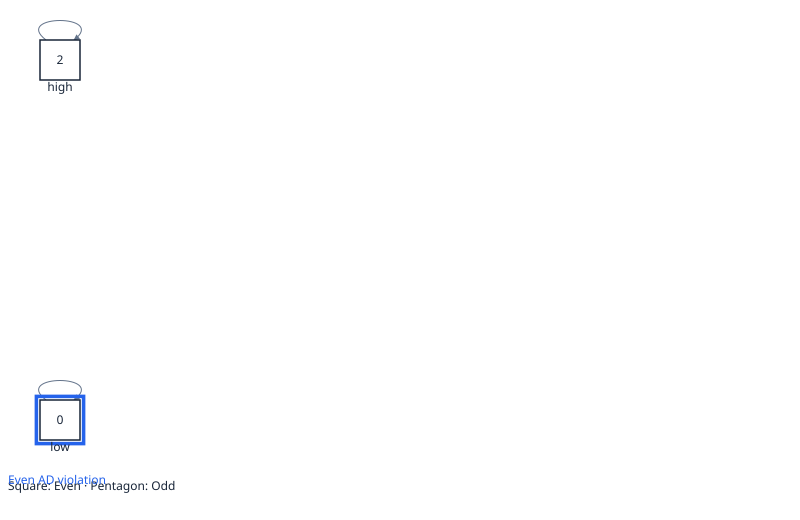

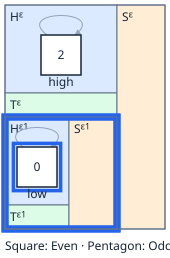

Repaired tree: CheckResult(ok=True, condition=<Condition.OK: 0>, path=(), vertex=None, message='', violations=())


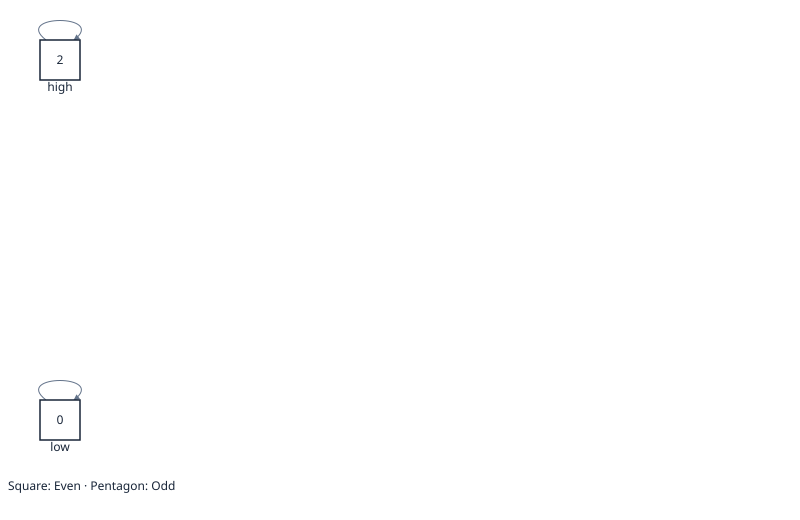

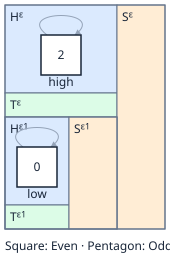

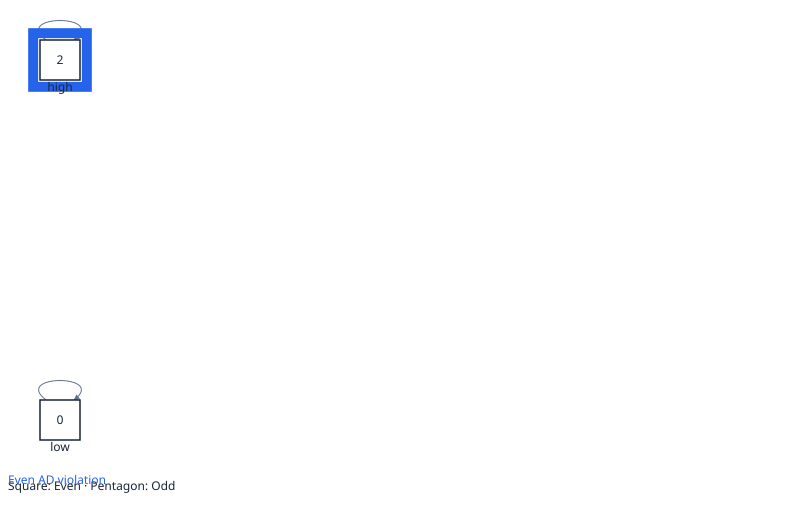

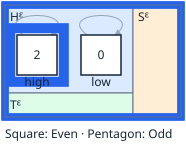

Top-priority vertex failure: CheckResult(ok=False, condition=<Condition.PRIORITY: 4>, path=(), vertex=0, message='a domain priority exceeds the node bound', violations=(Violation(condition=<Condition.PRIORITY: 4>, path=(), vertex=0, edge=None), Violation(condition=<Condition.TOP: 5>, path=(), vertex=0, edge=None), Violation(condition=<Condition.PRIORITY: 4>, path=(), vertex=0, edge=None)))


In [2]:
from copy import deepcopy
game = strahler.Game.from_text('0 2 0 0 "high"; 1 0 0 1 "low";')
good = dict(h=2, H=[0], T=[], S=[], children=[
    dict(h=0, H=[1], T=[], S=[], children=[])])
bad = deepcopy(good)
bad["children"][0]["h"] = 2
failure = strahler.check(game, bad, 0)
assert not failure.ok and failure.path == (0,) and failure.condition is strahler.Condition.CHILD
print("Child bound failure:", failure)
view = GameView(game)
candidate = TreeView(bad, view)
view.show_check(failure, 0)
candidate.show_check(failure, 0)
display(view, candidate)
bad["children"][0]["h"] = 0
fixed = strahler.check(game, bad, 0)
assert fixed.ok
print("Repaired tree:", fixed)
repaired_view = GameView(game)
repaired_candidate = TreeView(bad, repaired_view)
repaired_view.show_check(fixed, 0)
repaired_candidate.show_check(fixed, 0)
display(repaired_view, repaired_candidate)
wrong_top = dict(h=0, H=[0, 1], T=[], S=[], children=[])
located = strahler.check(game, wrong_top, 0)
assert not located.ok and located.vertex == 0 and located.condition is strahler.Condition.PRIORITY
priority_view = GameView(game)
priority_view.show_check(located, 0)
wrong_view = TreeView(wrong_top, priority_view)
wrong_view.show_check(located, 0)
display(priority_view, wrong_view)
print("Top-priority vertex failure:", located)

The next candidate has two failures: a trap escape and a missing attractor
vertex. The checker keeps its first verdict and also lists both witnesses.


(Violation(condition=<Condition.TRAP: 7>, path=(0,), vertex=20, edge=(20, 30)), Violation(condition=<Condition.ATTRACTOR: 9>, path=(1,), vertex=40, edge=(40, 30)))


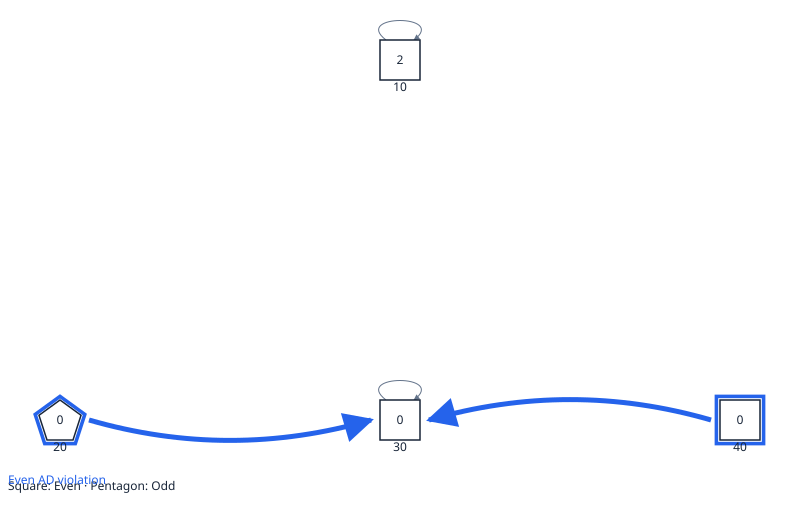

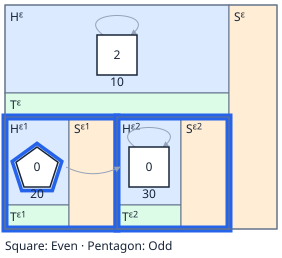

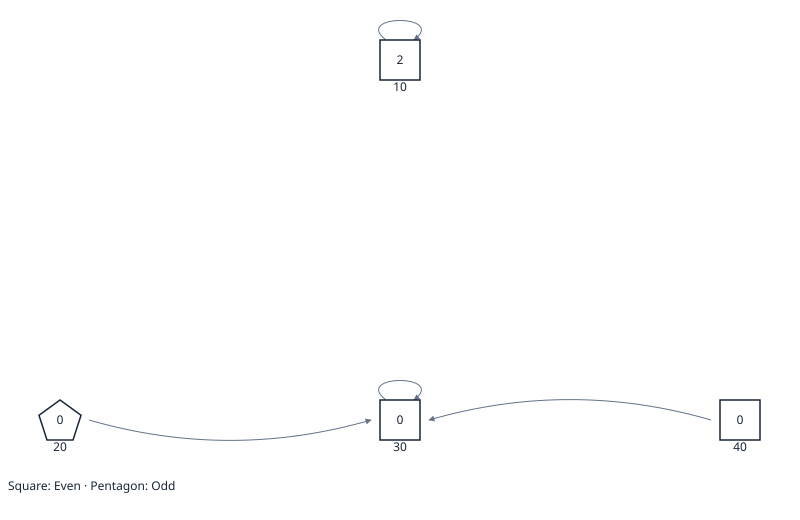

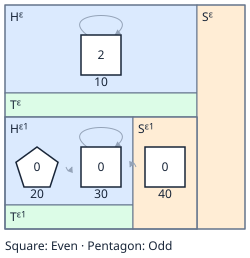

In [3]:
escape_game = strahler.Game.from_text('10 2 0 10;20 0 1 30;30 0 0 30;40 0 0 30;')
escape_tree = dict(h=2, H=[10], T=[], S=[], children=[
    dict(h=0, H=[20], T=[], S=[], children=[]),
    dict(h=0, H=[30], T=[], S=[], children=[])])
escape_view = GameView(escape_game)
escape_candidate = TreeView(escape_tree, escape_view)
verdict = strahler.check(escape_game, escape_tree, 0)
assert len(verdict.violations) == 2 and verdict.violations[0].edge == (20, 30)
escape_view.show_check(verdict, 0)
escape_candidate.show_check(verdict, 0)
print(verdict.violations)
display(escape_view, escape_candidate)
# Repair the trap and put the attracted vertex in its side part.
escape_tree['children'] = [dict(h=0, H=[20, 30], T=[], S=[40], children=[])]
verdict = strahler.check(escape_game, escape_tree, 0)
assert verdict.ok
repaired_escape_view = GameView(escape_game)
repaired_escape_candidate = TreeView(escape_tree, repaired_escape_view)
repaired_escape_view.show_check(verdict, 0)
repaired_escape_candidate.show_check(verdict, 0)
display(repaired_escape_view, repaired_escape_candidate)


Try a JSON tree in the editor below. "Check tree" reports malformed input or
the independent verdict, including failure locations. The initial check runs
automatically. For a single winning region, pass that region as `subgame=`;
the induced subgame must be total. An empty restriction is valid.

In [4]:
import json
from ipywidgets import Textarea, Button, Output, VBox
field = Textarea(value=json.dumps(good, indent=2), description="Tree JSON", layout={"width": "100%", "height": "240px"})
button = Button(description="Check tree")
output = Output()
editor_view = GameView(game)
def inspect_tree(_=None):
    with output:
        output.clear_output(wait=True)
        try:
            tree = json.loads(field.value)
            verdict = strahler.check(game, tree, 0)
            print(verdict)
            candidate = TreeView(tree, editor_view)
            editor_view.show_check(verdict, 0)
            candidate.show_check(verdict, 0)
            display(editor_view, candidate)
        except (ValueError, strahler.StrahlerError) as error:
            print(f"Invalid tree: {error}")
button.on_click(inspect_tree)
inspect_tree()
display(VBox([field, button, output]))

Static widget snapshot; rerun for interactive controls.